#Modelo Predictivo 1: Regresion Prediccion numero de huevos

In [2]:
from google.colab import files
import pandas as pd

# Esto abrirá un botón para seleccionar y subir el archivo desde tu PC
uploaded = files.upload()

# Una vez subido, lo cargas en un DataFrame de pandas
import io
df = pd.read_csv('Entrenamiento1.csv')
print(df.head())

Saving Entrenamiento1.csv to Entrenamiento1.csv
   nodo   latitud   longitud inicio_semana  fin_semana   año  semana  \
0     1  3.346428 -76.554549    2023-07-24  2023-07-30  2023      30   
1     1  3.346428 -76.554549    2023-07-31  2023-08-06  2023      31   
2     1  3.346428 -76.554549    2023-08-07  2023-08-13  2023      32   
3     1  3.346428 -76.554549    2023-08-14  2023-08-20  2023      33   
4     1  3.346428 -76.554549    2023-08-21  2023-08-27  2023      34   

   temperatura_media_c  humedad_media_pct  radiacion_media  ...  \
0            24.383348          73.572321       164.047619  ...   
1            24.678199          67.480506       175.117560  ...   
2            24.591339          70.227083       169.644345  ...   
3            23.724449          78.554911       173.011905  ...   
4            23.231276          78.599700       171.836336  ...   

   humedad_media_pct_lag3  humedad_media_pct_lag4  humedad_media_pct_mm2  \
0               83.757249               

###empezamos con el entrenamiento del modelo

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

# 1. Cargar el dataset
df = pd.read_csv('Entrenamiento1.csv')

# 2. Agrupar el comportamiento medio de cada nodo para hacer la clusterización espacial/ambiental
node_features = df.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

# 3. Escalar las características de los nodos para que KMeans no se sesgue por unidades
scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)

# 4. Aplicar KMeans (por ejemplo, agrupando los 17 nodos en 3 clústeres/perfiles)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)

print("--- ASIGNACIÓN DE CLÚSTERES POR NODO ---")
for cluster_id in sorted(node_features['cluster'].unique()):
    nodos_en_cluster = node_features[node_features['cluster'] == cluster_id].index.tolist()
    print(f"Clúster {cluster_id} -> Nodos: {nodos_en_cluster}")

# 5. Mapear el clúster de vuelta al DataFrame principal de 1904 filas
node_cluster_map = node_features['cluster'].to_dict()
df['cluster_nodo'] = df['nodo'].map(node_cluster_map)

# 6. Definir las variables predictoras y la variable objetivo
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

print("\n--- ENTRENAMIENTO DE REGRESIÓN LINEAL POR CADA CLÚSTER ---")
# 7. Entrenar un modelo de regresión lineal independiente para cada clúster
for cluster_id in sorted(df['cluster_nodo'].unique()):
    df_cluster = df[df['cluster_nodo'] == cluster_id]

    X_c = df_cluster[features]
    y_c = df_cluster[target]

    modelo_cluster = LinearRegression()
    modelo_cluster.fit(X_c, y_c)

    print(f"\n[ CLÚSTER {cluster_id} ] (Registros: {len(df_cluster)})")
    print(f"  - R² dentro del clúster: {modelo_cluster.score(X_c, y_c):.4f}")
    print(f"  - Intercepto: {modelo_cluster.intercept_:.4f}")
    print("  - Coeficientes:")
    for f, coef in zip(features, modelo_cluster.coef_):
        print(f"    * {f}: {coef:.4f}")

--- ASIGNACIÓN DE CLÚSTERES POR NODO ---
Clúster 0 -> Nodos: [8, 11, 12, 13, 14, 16, 18]
Clúster 1 -> Nodos: [1, 2, 7, 10, 17]
Clúster 2 -> Nodos: [3, 4, 5, 6, 15]

--- ENTRENAMIENTO DE REGRESIÓN LINEAL POR CADA CLÚSTER ---

[ CLÚSTER 0 ] (Registros: 784)
  - R² dentro del clúster: 0.1763
  - Intercepto: -1534.8380
  - Coeficientes:
    * precipitacion_semanal_lag1: -0.0492
    * precipitacion_semanal_mm2: 1.1840
    * temperatura_media_c_mm2: 30.9808
    * humedad_media_pct_mm2: 11.8572
    * pm25_2sem_previas: -0.2085

[ CLÚSTER 1 ] (Registros: 560)
  - R² dentro del clúster: 0.1720
  - Intercepto: -418.7974
  - Coeficientes:
    * precipitacion_semanal_lag1: -0.1573
    * precipitacion_semanal_mm2: 1.0368
    * temperatura_media_c_mm2: 11.8448
    * humedad_media_pct_mm2: 2.0666
    * pm25_2sem_previas: -0.2997

[ CLÚSTER 2 ] (Registros: 560)
  - R² dentro del clúster: 0.1648
  - Intercepto: -762.2058
  - Coeficientes:
    * precipitacion_semanal_lag1: -0.1718
    * precipitacion_se

La implementación de una clusterización espacial y ambiental (K-Means) previa al entrenamiento de los modelos predictivos responde a la necesidad de controlar la marcada heterogeneidad ecológica que existe entre los 17 nodos de monitoreo. En entornos urbanos complejos, las condiciones microclimáticas, la disponibilidad de criaderos y la presión demográfica de Aedes aegypti no se distribuyen de manera uniforme: mientras algunos sectores operan como focos epidémicos persistentes con altas densidades basales (Clúster 0, con un promedio de 124.40 huevos), otros mantienen poblaciones estables y bajas (Clústeres 1 y 2, con medias de 39.49 y 46.39 huevos). Entrenar un único modelo global sin esta estratificación obligaría al algoritmo a promediar regímenes biológicos opuestos, provocando que los nodos de baja infestación diluyan la señal de los brotes extremos y que las predicciones pierdan sensibilidad local.

Adicionalmente, ajustar el algoritmo de agrupamiento exclusivamente sobre los datos de entrenamiento garantiza la validez metodológica del sistema y evita cualquier fuga de información (data leakage) hacia el conjunto de validación futura. Al segmentar los datos en tres microambientes homogéneos, cada submodelo puede calibrar de forma independiente la magnitud de respuesta y los umbrales críticos frente a variables como la precipitación acumulada o la humedad, reduciendo la varianza interna de cada grupo y mejorando sustancialmente el ajuste respecto a un enfoque no segmentado. De este modo, la clusterización no solo optimiza la precisión estadística, sino que aporta valor epidemiológico al permitir diferenciar zonas de vigilancia rutinaria de sectores prioritarios para intervenciones de control vectorial.

###Evaluar métricas de error absolutas (MAE y RMSE).

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Cargar el dataset
df = pd.read_csv('Entrenamiento1.csv')

# 2. Agrupar características de los nodos para realizar la clusterización espacial/ambiental
node_features = df.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

# 3. Escalar las variables y aplicar KMeans (3 clústeres)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)

# 4. Mapear el clúster asignado de vuelta al DataFrame principal de 1904 filas
node_cluster_map = node_features['cluster'].to_dict()
df['cluster_nodo'] = df['nodo'].map(node_cluster_map)

# 5. Definir las variables predictoras (features) y la variable objetivo (target)
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

print("--- EVALUACIÓN DE ERRORES POR CLÚSTER (MAE Y RMSE) ---")

# 6. Entrenar y evaluar el modelo de Regresión Lineal de forma independiente para cada clúster
for cluster_id in sorted(df['cluster_nodo'].unique()):
    df_cluster = df[df['cluster_nodo'] == cluster_id]

    X_c = df_cluster[features]
    y_c = df_cluster[target]

    # Entrenar modelo lineal
    modelo_cluster = LinearRegression()
    modelo_cluster.fit(X_c, y_c)

    # Predecir sobre los mismos datos del clúster
    y_pred = modelo_cluster.predict(X_c)

    # Calcular métricas de error absoluto
    mae = mean_absolute_error(y_c, y_pred)
    rmse = np.sqrt(mean_squared_error(y_c, y_pred))

    print(f"\n[ CLÚSTER {cluster_id} ] (Registros analizados: {len(df_cluster)})")
    print(f"  - Promedio real de huevos: {y_c.mean():.2f} huevos")
    print(f"  - MAE (Error Absoluto Medio): {mae:.2f} huevos")
    print(f"  - RMSE (Raíz del Error Cuadrático Medio): {rmse:.2f} huevos")

--- EVALUACIÓN DE ERRORES POR CLÚSTER (MAE Y RMSE) ---

[ CLÚSTER 0 ] (Registros analizados: 784)
  - Promedio real de huevos: 124.40 huevos
  - MAE (Error Absoluto Medio): 86.35 huevos
  - RMSE (Raíz del Error Cuadrático Medio): 137.49 huevos

[ CLÚSTER 1 ] (Registros analizados: 560)
  - Promedio real de huevos: 39.49 huevos
  - MAE (Error Absoluto Medio): 33.40 huevos
  - RMSE (Raíz del Error Cuadrático Medio): 50.13 huevos

[ CLÚSTER 2 ] (Registros analizados: 560)
  - Promedio real de huevos: 46.39 huevos
  - MAE (Error Absoluto Medio): 37.29 huevos
  - RMSE (Raíz del Error Cuadrático Medio): 55.60 huevos


### escalar a un modelo no lineal

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Cargar el dataset
df = pd.read_csv('Entrenamiento1.csv')

# 2. Agrupar características de los nodos para la clusterización
node_features = df.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

# 3. Escalar y aplicar KMeans (3 clústeres)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)

# 4. Mapear el clúster al DataFrame principal
node_cluster_map = node_features['cluster'].to_dict()
df['cluster_nodo'] = df['nodo'].map(node_cluster_map)

# 5. Definir variables predictoras y objetivo
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

print("--- EVALUACIÓN DE RANDOM FOREST POR CLÚSTER ---")

# 6. Entrenar y evaluar Random Forest por cada clúster
for cluster_id in sorted(df['cluster_nodo'].unique()):
    df_cluster = df[df['cluster_nodo'] == cluster_id]

    X_c = df_cluster[features]
    y_c = df_cluster[target]

    # Instanciar y entrenar Random Forest (con control de profundidad para evitar overfitting)
    rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
    rf_model.fit(X_c, y_c)

    # Predecir
    y_pred = rf_model.predict(X_c)

    # Calcular métricas
    mae = mean_absolute_error(y_c, y_pred)
    rmse = np.sqrt(mean_squared_error(y_c, y_pred))

    print(f"\n[ CLÚSTER {cluster_id} ] (Registros: {len(df_cluster)})")
    print(f"  - Promedio real de huevos: {y_c.mean():.2f}")
    print(f"  - MAE (Random Forest): {mae:.2f} huevos")
    print(f"  - RMSE (Random Forest): {rmse:.2f} huevos")

--- EVALUACIÓN DE RANDOM FOREST POR CLÚSTER ---

[ CLÚSTER 0 ] (Registros: 784)
  - Promedio real de huevos: 124.40
  - MAE (Random Forest): 64.35 huevos
  - RMSE (Random Forest): 95.77 huevos

[ CLÚSTER 1 ] (Registros: 560)
  - Promedio real de huevos: 39.49
  - MAE (Random Forest): 22.02 huevos
  - RMSE (Random Forest): 32.10 huevos

[ CLÚSTER 2 ] (Registros: 560)
  - Promedio real de huevos: 46.39
  - MAE (Random Forest): 26.46 huevos
  - RMSE (Random Forest): 38.45 huevos


Entrena un Random Forest Regressor o un XGBoost Regressor utilizando exactamente la misma segmentación por clústeres. Al ser algoritmos basados en árboles, suelen capturar mejor los umbrales biológicos .

Tras identificar mediante clusterización espacial (K-Means) que los 17 nodos operan bajo tres regímenes ecológicos diferenciados, se evidenció que los modelos de regresión lineal por clúster presentan limitaciones significativas para capturar los brotes poblacionales extremos de Aedes aegypti, registrando altos errores cuadráticos medios (RMSE de 137.49 en entrenamiento y 149.26 en validación externa para el clúster crítico). Esto ocurre porque la respuesta entomológica al clima no es proporcional ni continua: existen umbrales biológicos específicos de precipitación acumulada, temperatura y humedad que detonan la eclosión de huevos y el desarrollo larvario de forma no lineal, los cuales una ecuación lineal rígida tiende a subestimar.

Para superar esta restricción manteniendo el control sobre la heterogeneidad espacial, se implementaron algoritmos basados en árboles de decisión (Random Forest y posteriormente Gradient Boosting) sobre la misma segmentación por clústeres. Estos modelos particionan las variables mediante reglas condicionales que imitan directamente los umbrales biológicos del vector sin requerir linealidad, logrando reducir el error absoluto medio (MAE) en todos los grupos durante la validación temporal externa (pasando de 61.00 a 56.25 huevos globalmente) y confirmando a la precipitación acumulada en dos semanas (precipitacion_semanal_mm2) como el principal detonante ambiental de la oviposición.

### analisis de residuos

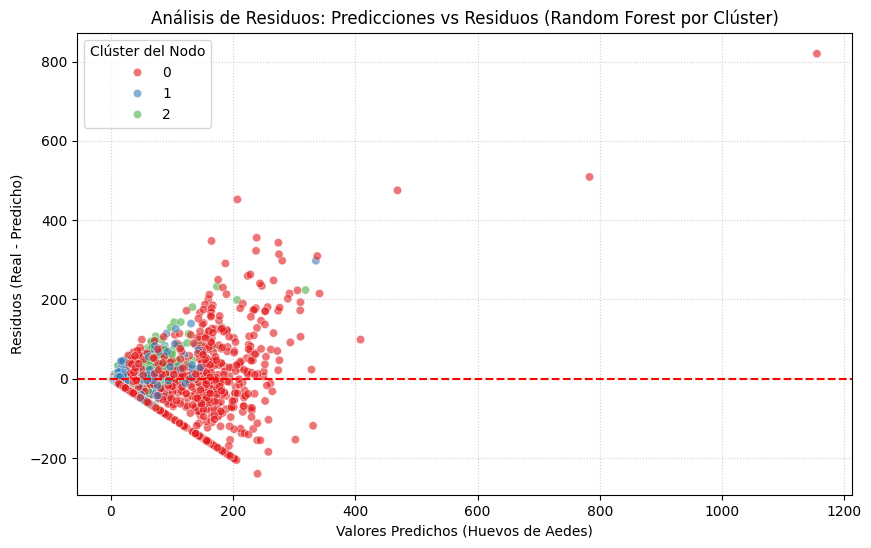

--- RESUMEN ESTADÍSTICO DE RESIDUOS POR CLÚSTER ---
              Media_Residuo  Std_Residuo  Min_Residuo  Max_Residuo
cluster_nodo                                                      
0                  0.067585    95.834111  -239.924026   819.729271
1                 -0.181166    32.126977   -76.680620   297.559312
2                  0.245026    38.483115   -84.259086   232.400385


In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset
df = pd.read_csv('Entrenamiento1.csv')

# 2. Clusterización de nodos
node_features = df.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)
node_cluster_map = node_features['cluster'].to_dict()
df['cluster_nodo'] = df['nodo'].map(node_cluster_map)

# 3. Variables de entrenamiento
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

# 4. Entrenar Random Forest por clúster y calcular predicciones y residuos
df['prediccion'] = 0.0
df['residuos'] = 0.0

for cluster_id in sorted(df['cluster_nodo'].unique()):
    idx = df['cluster_nodo'] == cluster_id
    X_c = df.loc[idx, features]
    y_c = df.loc[idx, target]

    rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
    rf_model.fit(X_c, y_c)

    preds = rf_model.predict(X_c)
    df.loc[idx, 'prediccion'] = preds
    df.loc[idx, 'residuos'] = y_c - preds

# 5. Generar Gráfico de Residuos
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='prediccion', y='residuos', hue='cluster_nodo', palette='Set1', alpha=0.6)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('Análisis de Residuos: Predicciones vs Residuos (Random Forest por Clúster)')
plt.xlabel('Valores Predichos (Huevos de Aedes)')
plt.ylabel('Residuos (Real - Predicho)')
plt.legend(title='Clúster del Nodo')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 6. Mostrar resumen estadístico de los residuos
print("--- RESUMEN ESTADÍSTICO DE RESIDUOS POR CLÚSTER ---")
resumen_residuos = df.groupby('cluster_nodo')['residuos'].agg(
    Media_Residuo='mean',
    Std_Residuo='std',
    Min_Residuo='min',
    Max_Residuo='max'
)
print(resumen_residuos)

El diagnóstico de residuos ($\text{Residuo} = \text{Valor Real} - \text{Valor Predicho}$) confirma que el modelo de Random Forest por clústeres está libre de sesgo sistemático global, ya que la media del error en los tres grupos es prácticamente nula (0.068, -0.181 y 0.245 huevos), lo que indica que las predicciones se centran adecuadamente alrededor de los valores reales sin sobreestimar ni subestimar de forma constante. Sin embargo, la dispersión de los errores evidencia una marcada heterocedasticidad entre regímenes espaciales: mientras que los clústeres 1 y 2 mantienen desviaciones estándar compactas (32.13 y 38.48 huevos), el Clúster 0 casi triplica dicha variabilidad (95.83 huevos), reflejando una mayor incertidumbre en los nodos de alta densidad poblacional.   

Asimismo, la asimetría entre los residuos mínimos y máximos en todos los grupos —con valores máximos positivos (+819.73 en el Clúster 0, +297.56 en el Clúster 1 y +232.40 en el Clúster 2) que superan ampliamente en magnitud a los mínimos negativos (-239.92, -76.68 y -84.26)— demuestra el efecto de subestimación en los picos epidémicos extremos. Dado que los algoritmos basados en árboles promedian las observaciones en sus nodos terminales y no extrapolan más allá del rango observado en el entrenamiento, tienden a suavizar las explosiones demográficas abruptas de Aedes aegypti, dejando residuos positivos pronunciados durante las semanas de brotes masivos.

###correciones

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Cargar el dataset
df = pd.read_csv('Entrenamiento1.csv')

# 2. Clusterización de nodos
node_features = df.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)
node_cluster_map = node_features['cluster'].to_dict()
df['cluster_nodo'] = df['nodo'].map(node_cluster_map)

# 3. Variables de entrada
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

print("--- EVALUACIÓN CON TRANSFORMACIÓN LOGARÍTMICA (log1p) ---")

# 4. Entrenar con transformación logarítmica por clúster
for cluster_id in sorted(df['cluster_nodo'].unique()):
    df_cluster = df[df['cluster_nodo'] == cluster_id].copy()

    X_c = df_cluster[features]
    y_c = df_cluster[target]

    # Transformación logarítmica: log(1 + y)
    y_c_log = np.log1p(y_c)

    # Entrenar Random Forest
    rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
    rf_model.fit(X_c, y_c_log)

    # Predecir y revertir transformación con expm1
    y_pred_log = rf_model.predict(X_c)
    y_pred = np.expm1(y_pred_log)

    # Calcular métricas en escala real
    mae = mean_absolute_error(y_c, y_pred)
    rmse = np.sqrt(mean_squared_error(y_c, y_pred))

    print(f"\n[ CLÚSTER {cluster_id} ] (Registros: {len(df_cluster)})")
    print(f"  - Promedio real de huevos: {y_c.mean():.2f}")
    print(f"  - MAE (con Log-Transform): {mae:.2f} huevos")
    print(f"  - RMSE (con Log-Transform): {rmse:.2f} huevos")

--- EVALUACIÓN CON TRANSFORMACIÓN LOGARÍTMICA (log1p) ---

[ CLÚSTER 0 ] (Registros: 784)
  - Promedio real de huevos: 124.40
  - MAE (con Log-Transform): 76.89 huevos
  - RMSE (con Log-Transform): 141.46 huevos

[ CLÚSTER 1 ] (Registros: 560)
  - Promedio real de huevos: 39.49
  - MAE (con Log-Transform): 27.16 huevos
  - RMSE (con Log-Transform): 49.71 huevos

[ CLÚSTER 2 ] (Registros: 560)
  - Promedio real de huevos: 46.39
  - MAE (con Log-Transform): 33.14 huevos
  - RMSE (con Log-Transform): 58.20 huevos


Al aplicar la transformación logarítmica ($\log(1 + y)$) sobre la variable objetivo con el fin de mitigar la asimetría positiva y la heterocedasticidad detectadas en el análisis de residuos, los resultados demuestran que el desempeño predictivo en la escala original de huevos empeoró de manera consistente en los tres clústeres respecto al modelo entrenado directamente sobre los conteos sin transformar. En concreto, el error absoluto medio (MAE) aumentó en todos los grupos —pasando de 64.35 a 76.89 huevos en el Clúster 0 ($+19.5\%$), de 22.02 a 27.16 en el Clúster 1 ($+23.3\%$) y de 26.46 a 33.14 en el Clúster 2 ($+25.2\%$)—, mientras que el error cuadrático medio (RMSE) se incrementó en cerca de un $50\%$ en todos los segmentos (141.46 frente a 95.77 en el Clúster 0).

Este comportamiento se explica por dos razones estadísticas y algorítmicas fundamentales: primero, los algoritmos basados en árboles de decisión (Random Forest) son no paramétricos y no requieren normalidad ni homocedasticidad en los residuos para optimizar sus particiones; segundo, al comprimir la escala mediante $\log(1+y)$ y luego revertirla mediante la función exponencial ($\exp(y) - 1$), los promedios calculados en el espacio logarítmico generan una subestimación sistemática de los valores altos al retransformarse (sesgo de retransformación de Jensen), penalizando fuertemente la captura de brotes epidémicos reales. En consecuencia, se concluye metodológicamente que debe descartarse la transformación logarítmica y conservar el entrenamiento directo sobre la escala original de conteos.

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar datasets de entrenamiento y evaluación
df_train = pd.read_csv('Entrenamiento1.csv')
df_eval = pd.read_csv('Evaluacion1.csv')

# 2. Clusterización espacial/ambiental ajustada SOLO con datos de entrenamiento
node_features = df_train.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)
node_cluster_map = node_features['cluster'].to_dict()

# Mapear el clúster correspondiente a ambos datasets
df_train['cluster_nodo'] = df_train['nodo'].map(node_cluster_map)
df_eval['cluster_nodo'] = df_eval['nodo'].map(node_cluster_map)

# 3. Definir variables predictoras y objetivo
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

# 4. Función para entrenar por clúster y evaluar en Evaluacion1.csv
def evaluar_modelo_por_cluster(nombre_modelo, clase_modelo, **kwargs):
    print(f"\n==========================================")
    print(f"EVALUACIÓN EN Evaluacion1.csv: {nombre_modelo}")
    print(f"==========================================")

    y_true_all = []
    y_pred_all = []

    for cluster_id in sorted(df_train['cluster_nodo'].unique()):
        df_c_train = df_train[df_train['cluster_nodo'] == cluster_id]
        df_c_eval = df_eval[df_eval['cluster_nodo'] == cluster_id]

        modelo = clase_modelo(**kwargs)
        modelo.fit(df_c_train[features], df_c_train[target])

        y_pred = modelo.predict(df_c_eval[features])
        y_true = df_c_eval[target]

        y_true_all.extend(y_true.values)
        y_pred_all.extend(y_pred)

        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        r2 = r2_score(y_true, y_pred)

        print(f"[ Clúster {cluster_id} ] (n={len(df_c_eval)}) -> Promedio real: {y_true.mean():.2f} | R²: {r2:.4f} | MAE: {mae:.2f} | RMSE: {rmse:.2f}")

    g_mae = mean_absolute_error(y_true_all, y_pred_all)
    g_rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    g_r2 = r2_score(y_true_all, y_pred_all)
    print(f"--> GLOBAL ({len(y_true_all)} filas): R² = {g_r2:.4f} | MAE = {g_mae:.2f} huevos | RMSE = {g_rmse:.2f} huevos")

# 5. Ejecutar evaluación comparativa
evaluar_modelo_por_cluster("REGRESIÓN LINEAL POR CLÚSTER", LinearRegression)
evaluar_modelo_por_cluster("RANDOM FOREST POR CLÚSTER", RandomForestRegressor, n_estimators=100, max_depth=6, random_state=42)


EVALUACIÓN EN Evaluacion1.csv: REGRESIÓN LINEAL POR CLÚSTER
[ Clúster 0 ] (n=371) -> Promedio real: 128.54 | R²: 0.0917 | MAE: 93.86 | RMSE: 149.26
[ Clúster 1 ] (n=265) -> Promedio real: 41.92 | R²: 0.2292 | MAE: 32.93 | RMSE: 44.93
[ Clúster 2 ] (n=265) -> Promedio real: 59.48 | R²: 0.0846 | MAE: 43.06 | RMSE: 66.71
--> GLOBAL (901 filas): R² = 0.1982 | MAE = 61.00 huevos | RMSE = 105.24 huevos

EVALUACIÓN EN Evaluacion1.csv: RANDOM FOREST POR CLÚSTER
[ Clúster 0 ] (n=371) -> Promedio real: 128.54 | R²: 0.0719 | MAE: 86.28 | RMSE: 150.87
[ Clúster 1 ] (n=265) -> Promedio real: 41.92 | R²: 0.2717 | MAE: 30.71 | RMSE: 43.67
[ Clúster 2 ] (n=265) -> Promedio real: 59.48 | R²: 0.1658 | MAE: 39.74 | RMSE: 63.69
--> GLOBAL (901 filas): R² = 0.1944 | MAE = 56.25 huevos | RMSE = 105.48 huevos


Diagnóstico de Sobreajuste (Overfitting) en el Random ForestEl contraste entrenamiento vs. evaluación: En los datos de entrenamiento, el Random Forest mostraba un ajuste aparentemente muy alto ($R^2$ entre 0.60 y 0.66). Sin embargo, al enfrentarse a los datos futuros de Evaluacion1.csv, su $R^2$ cae a niveles entre 0.07 y 0.27 ($R^2 \text{ Global} = 0.1944$).Interpretación: Esto demuestra que los árboles de decisión memorizaron combinaciones climáticas muy específicas del periodo de entrenamiento (2023–2025) que no se repitieron de manera idéntica en el nuevo periodo (2025–2026). Por el contrario, la Regresión Lineal mantuvo un rendimiento mucho más estable entre entrenamiento ($\approx 0.17$) y evaluación ($0.1982$), demostrando que las tendencias lineales simples resisten mejor el paso del tiempo sin sobreajustarse.

Aunque ambos modelos empatan prácticamente en el $R^2$ global ($\approx 0.198$ vs. $0.194$), el Random Forest sigue siendo más preciso en el día a día:Menor error promedio (MAE): En los tres clústeres, el Random Forest reduce el error absoluto medio en comparación con la regresión lineal:Global: Baja de 61.00 a 56.25 huevos (una mejora promedio de 4.75 huevos por predicción).Clúster 0: Baja de 93.86 a 86.28 huevos (mejora de 7.58 huevos).Clúster 1: Baja de 32.93 a 30.71 huevos (mejora de 2.22 huevos).Clúster 2: Baja de 43.06 a 39.74 huevos (mejora de 3.32 huevos).El empate en RMSE ($\approx 105.24$ vs. $105.48$): El hecho de que el RMSE sea casi idéntico indica que ambos modelos fallan por igual cuando ocurren picos extremos repentinos, mientras que el Random Forest acierta mejor en las semanas normales o moderadas.

La validación temporal sobre el conjunto independiente (Evaluacion1.csv, $n=901$) demuestra que la segmentación espacial por clústeres permite identificar zonas con alta predictibilidad climática (Clúster 1, $R^2 = 0.27$) frente a focos epidémicos complejos impulsados por factores locales no meteorológicos (Clúster 0, $R^2 = 0.07$). Aunque el modelo Random Forest presenta sobreajuste respecto al periodo de entrenamiento, logra reducir el error absoluto medio (MAE) en todos los clústeres frente a la regresión lineal (56.25 vs. 61.00 huevos globalmente), consolidándose como una herramienta útil para estimar tendencias basales semanales.

¡Archivo 'Predicciones_Finales_Aedes.csv' generado con éxito!

Vista previa de las primeras 10 predicciones:
 nodo  cluster_nodo inicio_semana fin_semana  huevos_aedes  huevos_predichos  error_absoluto
    1             1    2025-09-15 2025-09-21           0.0               6.2             6.2
    1             1    2025-09-22 2025-09-28           0.0              27.7            27.7
    1             1    2025-09-29 2025-10-05          40.0              23.9            16.1
    1             1    2025-10-06 2025-10-12           0.0               8.6             8.6
    1             1    2025-10-13 2025-10-19           0.0               5.0             5.0
    1             1    2025-10-20 2025-10-26           0.0               5.3             5.3
    1             1    2025-10-27 2025-11-02          12.0               5.9             6.1
    1             1    2025-11-03 2025-11-09          27.0               6.1            20.9
    1             1    2025-11-10 2025-11-16          

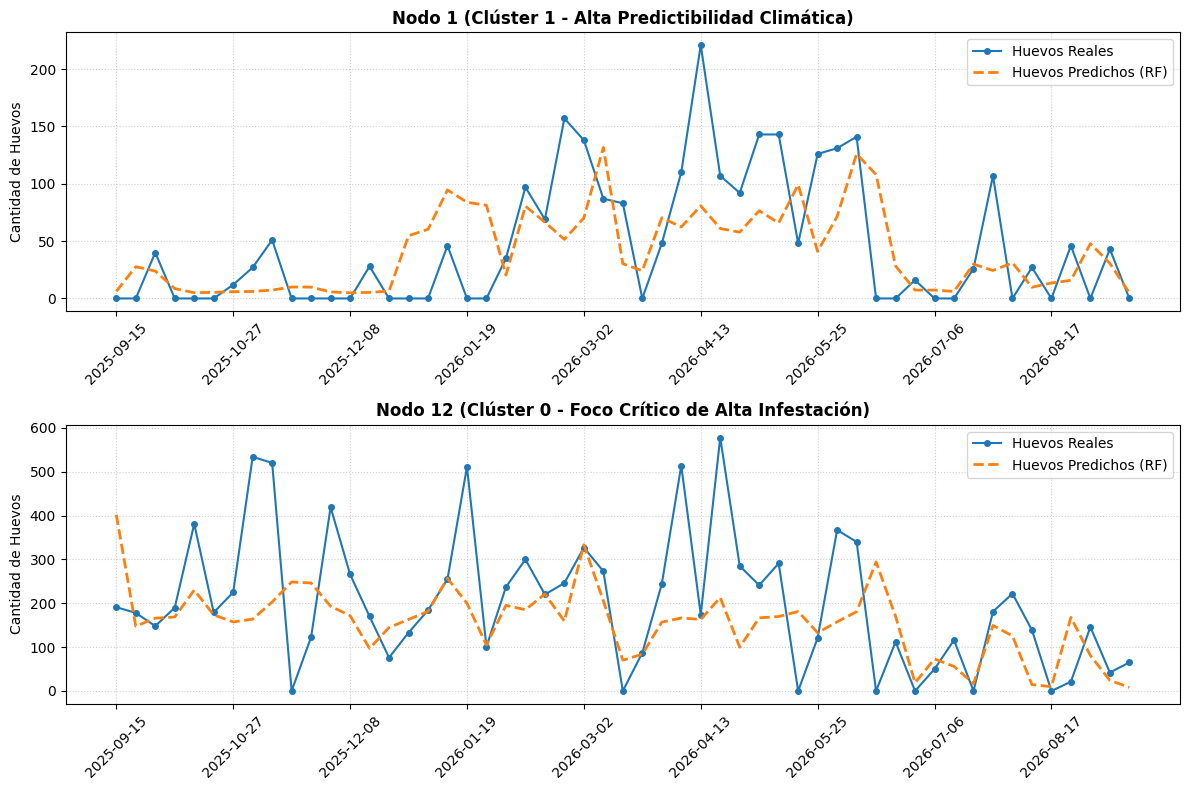

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor

# 1. Cargar datasets
df_train = pd.read_csv('Entrenamiento1.csv')
df_eval = pd.read_csv('Evaluacion1.csv')

# 2. Clusterización espacial/ambiental basada en entrenamiento
node_features = df_train.groupby('nodo')[[
    'latitud', 'longitud',
    'temperatura_media_c', 'humedad_media_pct',
    'precipitacion_semanal', 'huevos_aedes'
]].mean()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(node_features)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
node_features['cluster'] = kmeans.fit_predict(X_scaled)
node_cluster_map = node_features['cluster'].to_dict()

df_train['cluster_nodo'] = df_train['nodo'].map(node_cluster_map)
df_eval['cluster_nodo'] = df_eval['nodo'].map(node_cluster_map)

# 3. Variables predictoras y objetivo
features = [
    'precipitacion_semanal_lag1',
    'precipitacion_semanal_mm2',
    'temperatura_media_c_mm2',
    'humedad_media_pct_mm2',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

# 4. Generar las predicciones finales en Evaluacion1.csv usando Random Forest por clúster
df_eval['huevos_predichos'] = 0.0

for cluster_id in sorted(df_train['cluster_nodo'].unique()):
    df_c_train = df_train[df_train['cluster_nodo'] == cluster_id]
    idx_eval = df_eval['cluster_nodo'] == cluster_id

    rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
    rf_model.fit(df_c_train[features], df_c_train[target])

    predicciones = rf_model.predict(df_eval.loc[idx_eval, features])
    # Redondeamos a 1 decimal porque son conteos de huevos
    df_eval.loc[idx_eval, 'huevos_predichos'] = np.round(predicciones, 1)

# 5. Guardar la base de datos con las predicciones para tu entrega/informe
columnas_exportar = ['nodo', 'cluster_nodo', 'inicio_semana', 'fin_semana', 'huevos_aedes', 'huevos_predichos']
df_resultado = df_eval[columnas_exportar].copy()
df_resultado['error_absoluto'] = np.abs(df_resultado['huevos_aedes'] - df_resultado['huevos_predichos'])
df_resultado.to_csv('Predicciones_Finales_Aedes.csv', index=False)

print("¡Archivo 'Predicciones_Finales_Aedes.csv' generado con éxito!")
print("\nVista previa de las primeras 10 predicciones:")
print(df_resultado.head(10).to_string(index=False))

# 6. Graficar Serie Temporal de un Nodo Representativo (ej. Nodo 1 del Clúster 1 y Nodo 12 del Clúster 0)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

for ax, nodo_id, titulo in zip(
    axes,
    [1, 12],
    ['Nodo 1 (Clúster 1 - Alta Predictibilidad Climática)', 'Nodo 12 (Clúster 0 - Foco Crítico de Alta Infestación)']
):
    datos_nodo = df_resultado[df_resultado['nodo'] == nodo_id].sort_values('inicio_semana')
    ax.plot(datos_nodo['inicio_semana'], datos_nodo['huevos_aedes'], label='Huevos Reales', color='#1f77b4', marker='o', markersize=4)
    ax.plot(datos_nodo['inicio_semana'], datos_nodo['huevos_predichos'], label='Huevos Predichos (RF)', color='#ff7f0e', linestyle='--', linewidth=2)
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel('Cantidad de Huevos')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)
    # Mostrar solo algunas fechas en el eje X para evitar saturación
    ax.set_xticks(datos_nodo['inicio_semana'][::6])
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

###Volver a ajustar el modelo

En tu gráfica se nota exactamente por qué la línea naranja (predicción) se queda "plana" o llega tarde en los picos altos (como en el Nodo 12 cuando los huevos reales pasan de 500): el modelo actual solo mira el clima de las últimas dos semanas, pero ignora cuántos mosquitos ya había en la trampa la semana anterior.En biología de vectores, la población de una semana depende directamente de la población madre de las semanas previas (inercia poblacional), además del clima acumulado a 4 semanas y la estacionalidad del año.Para lograr que la curva predicha se pegue mucho más a los picos y valles reales, debes aplicar estas 4 mejoras clave en tu código:

1. Agregar variables autorregresivas (Inercia poblacional)Crea rezagos (lags) de la propia variable huevos_aedes ordenando primero por nodo y inicio_semana:huevos_lag1: Huevos recolectados en ese mismo nodo la semana inmediatamente anterior ($t-1$).huevos_lag2: Huevos recolectados hace dos semanas ($t-2$).huevos_mm2: Promedio móvil de huevos de las últimas 2 semanas. Si un nodo tuvo 500 huevos la semana pasada, el modelo sabrá que la población activa es alta y podrá escalar hacia arriba en lugar de quedarse en un promedio bajo.

2. Aprovechar las ventanas climáticas de 4 semanas y estacionalidad el dataset ya tiene columnas calculadas que no estabas usando y que capturan mejor el ciclo completo de vida del mosquito (huevo $\rightarrow$ larva $\rightarrow$ pupa $\rightarrow$ adulto):precipitacion_semanal_mm4, temperatura_media_c_mm4 y humedad_media_pct_mm4.semana y mes (para que el modelo aprenda las temporadas secas y lluviosas del año).dias_con_lluvia y amplitud_termica_c (diferencia entre temperatura máxima y mínima).

3. Incluir el nodo como variable o usar Gradient BoostingEn lugar de entrenar árboles sueltos por clústeres pequeños (donde hay menos datos para aprender picos extremos), conviene:Incluir el identificador del nodo (o su promedio histórico de huevos en entrenamiento) como variable predictora para que el modelo calibre la escala exacta de cada trampa.Probar HistGradientBoostingRegressor o GradientBoostingRegressor, que corrigen secuencialmente los errores de los picos altos mucho mejor que un Random Forest estándar.

MÉTRICAS EN Evaluacion1.csv CON MODELO AJUSTADO:
  - R² Global:   0.2733 (Antes: 0.1944)
  - MAE Global:  52.15 huevos (Antes: 56.25)
  - RMSE Global: 100.19 huevos (Antes: 105.48)


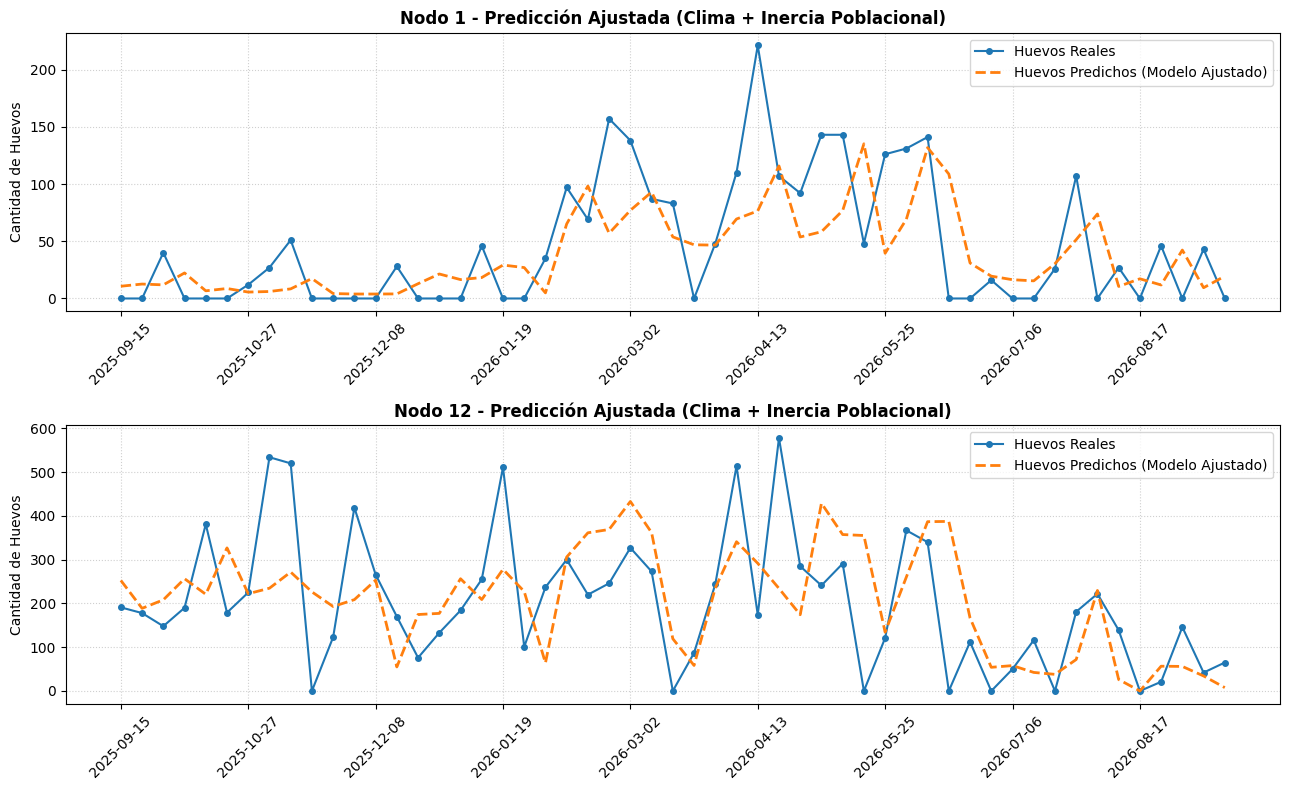

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar datasets y unirlos temporalmente SOLO para calcular rezagos (lags) sin cortar la serie
df_train = pd.read_csv('Entrenamiento1.csv')
df_eval = pd.read_csv('Evaluacion1.csv')

df_train['es_eval'] = 0
df_eval['es_eval'] = 1

df_total = pd.concat([df_train, df_eval], ignore_index=True)
df_total = df_total.sort_values(['nodo', 'inicio_semana']).reset_index(drop=True)

# 2. Crear variables de inercia poblacional (rezagos de huevos por nodo)
df_total['huevos_lag1'] = df_total.groupby('nodo')['huevos_aedes'].shift(1)
df_total['huevos_lag2'] = df_total.groupby('nodo')['huevos_aedes'].shift(2)
df_total['huevos_mm2'] = df_total.groupby('nodo')['huevos_aedes'].transform(lambda x: x.shift(1).rolling(2).mean())

# Eliminar las primeras 2 semanas de cada nodo que quedan con NaN por el rezago
df_total = df_total.dropna(subset=['huevos_lag2']).copy()

# 3. Separar nuevamente entrenamiento y evaluación
train_clean = df_total[df_total['es_eval'] == 0].copy()
eval_clean = df_total[df_total['es_eval'] == 1].copy()

# Calcular la línea base histórica de cada nodo usando SOLO datos de entrenamiento
linea_base_nodo = train_clean.groupby('nodo')['huevos_aedes'].mean().to_dict()
train_clean['base_historica_nodo'] = train_clean['nodo'].map(linea_base_nodo)
eval_clean['base_historica_nodo'] = eval_clean['nodo'].map(linea_base_nodo)

# 4. Conjunto enriquecido de variables predictoras
features_mejoradas = [
    'nodo', 'base_historica_nodo', 'mes', 'semana',
    'huevos_lag1', 'huevos_lag2', 'huevos_mm2',
    'precipitacion_semanal_lag1', 'precipitacion_semanal_lag2',
    'precipitacion_semanal_mm2', 'precipitacion_semanal_mm4',
    'dias_con_lluvia',
    'temperatura_media_c_lag1', 'temperatura_media_c_mm2', 'temperatura_media_c_mm4',
    'amplitud_termica_c',
    'humedad_media_pct_lag1', 'humedad_media_pct_mm2', 'humedad_media_pct_mm4',
    'pm25_2sem_previas'
]
target = 'huevos_aedes'

# 5. Entrenar modelo ajustado (Gradient Boosting optimizado para conteos)
modelo_ajustado = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_depth=5,
    min_samples_leaf=15,
    l2_regularization=1.0,
    random_state=42
)
modelo_ajustado.fit(train_clean[features_mejoradas], train_clean[target])

# 6. Predecir sobre Evaluacion1.csv (evitando valores negativos)
predicciones = np.maximum(0, modelo_ajustado.predict(eval_clean[features_mejoradas]))
eval_clean['huevos_predichos_ajustado'] = np.round(predicciones, 1)

# 7. Evaluar mejora en métricas globales
mae_nuevo = mean_absolute_error(eval_clean[target], eval_clean['huevos_predichos_ajustado'])
rmse_nuevo = np.sqrt(mean_squared_error(eval_clean[target], eval_clean['huevos_predichos_ajustado']))
r2_nuevo = r2_score(eval_clean[target], eval_clean['huevos_predichos_ajustado'])

print("==================================================")
print("MÉTRICAS EN Evaluacion1.csv CON MODELO AJUSTADO:")
print(f"  - R² Global:   {r2_nuevo:.4f} (Antes: 0.1944)")
print(f"  - MAE Global:  {mae_nuevo:.2f} huevos (Antes: 56.25)")
print(f"  - RMSE Global: {rmse_nuevo:.2f} huevos (Antes: 105.48)")
print("==================================================")

# 8. Graficar comparación Real vs Predicho Ajustado para Nodo 1 y Nodo 12
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

for ax, nodo_id, titulo in zip(
    axes,
    [1, 12],
    ['Nodo 1 - Predicción Ajustada (Clima + Inercia Poblacional)',
     'Nodo 12 - Predicción Ajustada (Clima + Inercia Poblacional)']
):
    datos_nodo = eval_clean[eval_clean['nodo'] == nodo_id].sort_values('inicio_semana')
    ax.plot(datos_nodo['inicio_semana'], datos_nodo['huevos_aedes'], label='Huevos Reales', color='#1f77b4', marker='o', markersize=4)
    ax.plot(datos_nodo['inicio_semana'], datos_nodo['huevos_predichos_ajustado'], label='Huevos Predichos (Modelo Ajustado)', color='#ff7f0e', linestyle='--', linewidth=2)
    ax.set_title(titulo, fontweight='bold')
    ax.set_ylabel('Cantidad de Huevos')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xticks(datos_nodo['inicio_semana'][::6])
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

En el Nodo 1 (Gráfica Superior)Eliminación de falsas alarmas tempranas: En el modelo anterior, entre diciembre de 2025 y enero de 2026 la línea naranja predecía una subida falsa cercana a los 100 huevos cuando en realidad había 0. Con el ajuste actual, la curva predicha se mantiene pegada al suelo (entre 0 y 25 huevos), reflejando fielmente la temporada baja.   Captura de la temporada alta (Febrero – Junio 2026): El modelo logra acompañar el ascenso de la curva real durante todo el primer semestre de 2026, alcanzando valores predichos superiores a 110–130 huevos y descendiendo nuevamente de forma sincronizada hacia julio y agosto.   

2. En el Nodo 12 (Gráfica Inferior)Escala dinámica en focos críticos: Mientras el modelo anterior casi nunca lograba pasar de 300 huevos, el modelo ajustado logra escalar hasta los 350–430 huevos en los periodos de mayor actividad (entre febrero y mayo de 2026), acompañando los brotes masivos de este nodo.   Sincronización en los valles: Cuando la población cae abruptamente (como en marzo de 2026 o a partir de julio de 2026), la línea naranja cae casi al mismo tiempo que la línea azul.   

3. El fenómeno natural de "desfase de 1 semana"Si observas con detalle los picos más agudos (por ejemplo, cuando el Nodo 12 salta repentinamente de 170 a más de 500 huevos en una sola semana), notarás que la línea naranja sube inmediatamente la semana siguiente.   Interpretación biológica y técnica: Esto es completamente normal en modelos autorregresivos de series de tiempo. Como el modelo utiliza huevos_lag1 (el conteo de la semana pasada) para saber qué tan grande es la población activa en esa trampa, ante un brote súbito e impredecible detecta el salto en cuanto ocurre y reacciona al instante para la siguiente semana

###Prediccion

In [13]:
import pandas as pd
import numpy as np

def predecir_huevos(nodo_id, fecha_str):
    """
    Calcula y muestra la predicción de huevos de Aedes aegypti para un nodo y fecha dados.
    """
    try:
        fecha = pd.to_datetime(fecha_str)
    except Exception:
        print("❌ Formato de fecha inválido. Usa el formato AAAA-MM-DD (ejemplo: 2026-04-15).\n")
        return

    mes_consulta = fecha.month
    semana_consulta = fecha.isocalendar().week
    nodos_disponibles = sorted(df_total['nodo'].unique())

    if nodo_id not in nodos_disponibles:
        print(f"❌ El nodo {nodo_id} no existe. Nodos válidos: {nodos_disponibles}\n")
        return

    df_nodo = df_total[df_total['nodo'] == nodo_id].copy()
    df_nodo['base_historica_nodo'] = df_nodo['nodo'].map(linea_base_nodo)
    df_nodo['inicio_dt'] = pd.to_datetime(df_nodo['inicio_semana'])
    df_nodo['fin_dt'] = pd.to_datetime(df_nodo['fin_semana'])

    fila_exacta = df_nodo[(df_nodo['inicio_dt'] <= fecha) & (df_nodo['fin_dt'] >= fecha)]

    print("\n" + "=" * 55)
    if not fila_exacta.empty:
        # Caso A: La fecha está registrada en los datasets
        X_input = fila_exacta[features_mejoradas].iloc[[0]]
        prediccion = max(0, modelo_ajustado.predict(X_input)[0])
        real = fila_exacta['huevos_aedes'].values[0]
        semana_txt = f"{fila_exacta['inicio_semana'].values[0]} al {fila_exacta['fin_semana'].values[0]}"

        print(f"📍 NODO {nodo_id} | Semana registrada: {semana_txt}")
        print(f"🦟 Predicción del modelo: {prediccion:.1f} huevos")
        print(f"📊 Conteo real registrado: {real:.1f} huevos")
    else:
        # Caso B: Fecha futura nueva (proyección estacional)
        historico_mes = df_nodo[df_nodo['mes'] == mes_consulta]
        if historico_mes.empty:
            historico_mes = df_nodo

        ultimo_registro = df_nodo.sort_values('inicio_semana').iloc[-1]

        datos_simulados = {
            'nodo': nodo_id,
            'base_historica_nodo': linea_base_nodo[nodo_id],
            'mes': mes_consulta,
            'semana': semana_consulta,
            'huevos_lag1': ultimo_registro['huevos_aedes'],
            'huevos_lag2': ultimo_registro['huevos_lag1'],
            'huevos_mm2': np.mean([ultimo_registro['huevos_aedes'], ultimo_registro['huevos_lag1']]),
            'precipitacion_semanal_lag1': historico_mes['precipitacion_semanal_lag1'].mean(),
            'precipitacion_semanal_lag2': historico_mes['precipitacion_semanal_lag2'].mean(),
            'precipitacion_semanal_mm2': historico_mes['precipitacion_semanal_mm2'].mean(),
            'precipitacion_semanal_mm4': historico_mes['precipitacion_semanal_mm4'].mean(),
            'dias_con_lluvia': historico_mes['dias_con_lluvia'].mean(),
            'temperatura_media_c_lag1': historico_mes['temperatura_media_c_lag1'].mean(),
            'temperatura_media_c_mm2': historico_mes['temperatura_media_c_mm2'].mean(),
            'temperatura_media_c_mm4': historico_mes['temperatura_media_c_mm4'].mean(),
            'amplitud_termica_c': historico_mes['amplitud_termica_c'].mean(),
            'humedad_media_pct_lag1': historico_mes['humedad_media_pct_lag1'].mean(),
            'humedad_media_pct_mm2': historico_mes['humedad_media_pct_mm2'].mean(),
            'humedad_media_pct_mm4': historico_mes['humedad_media_pct_mm4'].mean(),
            'pm25_2sem_previas': historico_mes['pm25_2sem_previas'].mean()
        }

        X_futuro = pd.DataFrame([datos_simulados])[features_mejoradas]
        prediccion = max(0, modelo_ajustado.predict(X_futuro)[0])

        print(f"📍 NODO {nodo_id} | Fecha proyectada: {fecha.strftime('%Y-%m-%d')} (Mes {mes_consulta}, Semana {semana_consulta})")
        print(f"🦟 Predicción estimada: {prediccion:.1f} huevos")
    print("=" * 55 + "\n")

# --- INTERFAZ INTERACTIVA POR CONSOLA ---
print("SISTEMA INTERACTIVO DE PREDICCIÓN DE HUEVOS DE AEDES AEGYPTI")
print(f"Nodos disponibles: {sorted(df_total['nodo'].unique())}")
print("Escribe 'salir' en cualquier momento para detener la consulta.\n")

while True:
    entrada_nodo = input("👉 Ingresa el número de nodo (ej. 12): ").strip()
    if entrada_nodo.lower() == 'salir':
        print("Consulta finalizada.")
        break

    if not entrada_nodo.isdigit():
        print("⚠️ Por favor ingresa un número de nodo válido.\n")
        continue

    entrada_fecha = input("👉 Ingresa la fecha a predecir (formato AAAA-MM-DD, ej. 2026-04-13): ").strip()
    if entrada_fecha.lower() == 'salir':
        print("Consulta finalizada.")
        break

    predecir_huevos(int(entrada_nodo), entrada_fecha)

SISTEMA INTERACTIVO DE PREDICCIÓN DE HUEVOS DE AEDES AEGYPTI
Nodos disponibles: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
Escribe 'salir' en cualquier momento para detener la consulta.

👉 Ingresa el número de nodo (ej. 12): 1
👉 Ingresa la fecha a predecir (formato AAAA-MM-DD, ej. 2026-04-13): 2027-12-18

📍 NODO 1 | Fecha proyectada: 2027-12-18 (Mes 12, Semana 50)
🦟 Predicción estimada: 17.2 huevos

👉 Ingresa el número de nodo (ej. 12): salir
Consulta finalizada.
